In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score
import pickle

%matplotlib inline
df = pd.read_csv("/kaggle/input/datasets/jamaltariqcheema/pima-indians-diabetes-dataset/diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


(768, 9)
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
       Pregnancies     Glucose  BloodPressure  SkinThickness     Insulin  \
count   768.000000  768.000000     768.000000     768.000000  768.000000   
mean      3.845052  121.677083      72.389323      29.089844  141.753906   
std       3.369578   30.464161      12.106039       8.890820   89.100847   
min       0.000000   44.000000      24.000000       7.000000   14.000000   
25%       1.000000   99.750000      64.000000      25.000000  102.500000   
50%       3.000000  117.000000      72.000000      28.000000  102.500000   
75%       6.000000  140.250000      80.000000      32.000000  169.500000   
max      17.000000  199.000000     122.000000      99.000000  846.000000   

              BMI  Diab

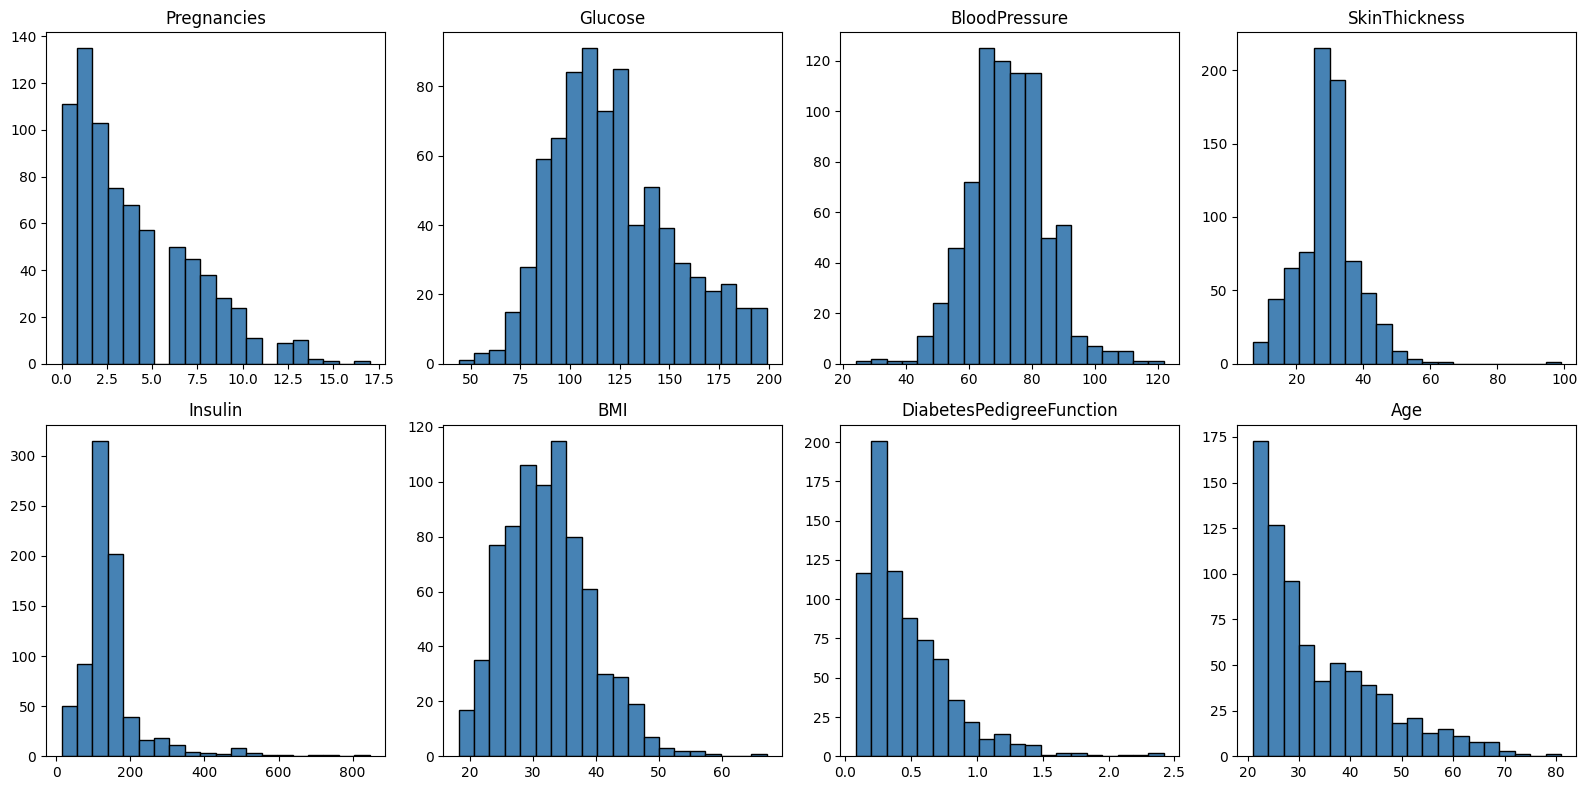

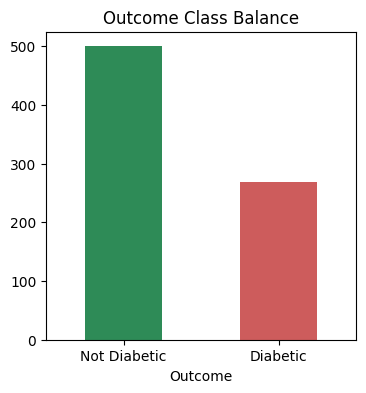

In [8]:
print(df.shape)
print(df.isnull().sum())
print(df.describe())

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]
for ax, col in zip(axes.flatten(), cols):
    ax.hist(df[col], bins=20, color="steelblue", edgecolor="black")
    ax.set_title(col)
plt.tight_layout()
plt.show()

plt.figure(figsize=(4, 4))
df["Outcome"].value_counts().plot(kind="bar", color=["seagreen", "indianred"])
plt.title("Outcome Class Balance")
plt.xticks([0, 1], ["Not Diabetic", "Diabetic"], rotation=0)
plt.show()

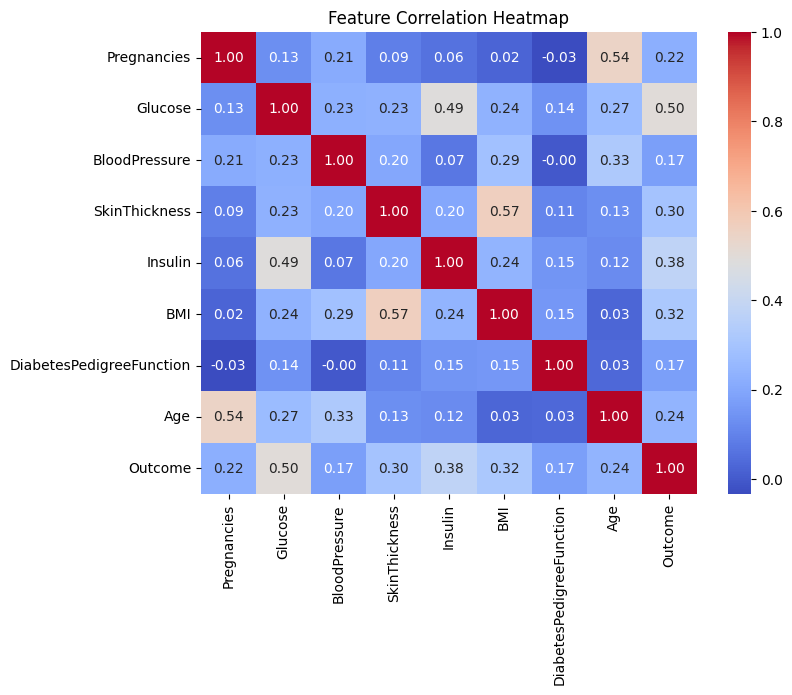

EDA Summary
Total records: 768
Total features: 8
Missing values: 0
Class distribution:
Outcome
0    500
1    268
Name: count, dtype: int64
Class ratio (Not Diabetic : Diabetic): 1.87 : 1
Feature with highest correlation to Outcome: Glucose


In [9]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

print("EDA Summary")
print("Total records:", df.shape[0])
print("Total features:", df.shape[1] - 1)
print("Missing values:", df.isnull().sum().sum())
print("Class distribution:")
print(df["Outcome"].value_counts())
print("Class ratio (Not Diabetic : Diabetic): {:.2f} : 1".format(
    df["Outcome"].value_counts()[0] / df["Outcome"].value_counts()[1]))
print("Feature with highest correlation to Outcome:",
      df.corr()["Outcome"].drop("Outcome").abs().idxmax())

In [20]:
zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in zero_as_missing:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].median())

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=20, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape:", X_train_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Train shape: (614, 8)
Test shape: (154, 8)


Client 1 samples: 205 positive cases: 73
Client 2 samples: 205 positive cases: 78
Client 3 samples: 204 positive cases: 63


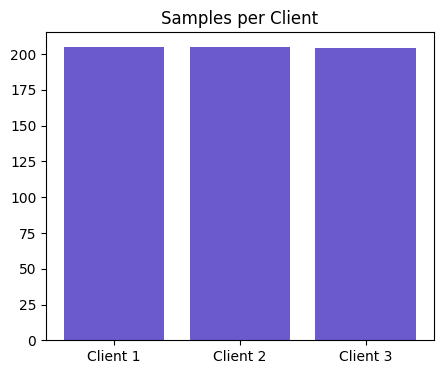

In [21]:
n_clients = 3
client_indices = np.array_split(np.arange(X_train_scaled.shape[0]), n_clients)

client_data = []
for idx in client_indices:
    X_c = X_train_scaled[idx]
    y_c = y_train.values[idx]
    client_data.append((X_c, y_c))

for i, (X_c, y_c) in enumerate(client_data):
    print("Client", i + 1, "samples:", X_c.shape[0], "positive cases:", int(y_c.sum()))

fig, ax = plt.subplots(figsize=(5, 4))
counts = [len(y_c) for _, y_c in client_data]
ax.bar(["Client 1", "Client 2", "Client 3"], counts, color="slateblue")
ax.set_title("Samples per Client")
plt.show()

In [22]:
from sklearn.linear_model import SGDClassifier

n_features = X_train_scaled.shape[1]
local_epochs = 3

def train_local_model(X_c, y_c, coef_init, intercept_init):
    model = SGDClassifier(loss="log_loss", max_iter=1, warm_start=True,
                           learning_rate="constant", eta0=0.05)
    model.classes_ = np.array([0, 1])
    model.coef_ = coef_init.copy()
    model.intercept_ = intercept_init.copy()
    for _ in range(local_epochs):
        model.partial_fit(X_c, y_c, classes=np.array([0, 1]))
    return model.coef_, model.intercept_

def federated_average(weights_list):
    coefs = np.array([w[0] for w in weights_list])
    intercepts = np.array([w[1] for w in weights_list])
    avg_coef = np.mean(coefs, axis=0)
    avg_intercept = np.mean(intercepts, axis=0)
    return avg_coef, avg_intercept

global_coef = np.zeros((1, n_features))
global_intercept = np.zeros(1)

print("Global model initialized")
print("Coefficient shape:", global_coef.shape)
print("Intercept shape:", global_intercept.shape)

Global model initialized
Coefficient shape: (1, 8)
Intercept shape: (1,)


Round 1 Global Test Accuracy: 0.8247
Round 2 Global Test Accuracy: 0.8182
Round 3 Global Test Accuracy: 0.8247
Round 4 Global Test Accuracy: 0.8182
Round 5 Global Test Accuracy: 0.8182
Round 6 Global Test Accuracy: 0.8312
Round 7 Global Test Accuracy: 0.8182
Round 8 Global Test Accuracy: 0.8182
Round 9 Global Test Accuracy: 0.8312
Round 10 Global Test Accuracy: 0.8312
Round 11 Global Test Accuracy: 0.8182
Round 12 Global Test Accuracy: 0.8247
Round 13 Global Test Accuracy: 0.8247
Round 14 Global Test Accuracy: 0.8247
Round 15 Global Test Accuracy: 0.8117


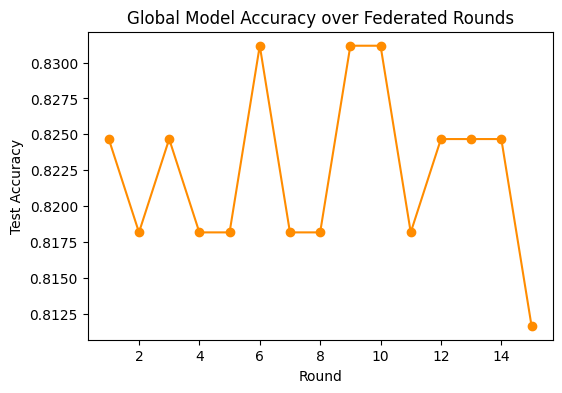

In [23]:
n_rounds = 15
round_accuracies = []

for r in range(n_rounds):
    client_weights = []
    for X_c, y_c in client_data:
        coef, intercept = train_local_model(X_c, y_c, global_coef, global_intercept)
        client_weights.append((coef, intercept))

    global_coef, global_intercept = federated_average(client_weights)

    eval_model = LogisticRegression(max_iter=1000)
    eval_model.coef_ = global_coef
    eval_model.intercept_ = global_intercept
    eval_model.classes_ = np.array([0, 1])
    preds = eval_model.predict(X_test_scaled)
    acc = accuracy_score(y_test, preds)
    round_accuracies.append(acc)
    print("Round", r + 1, "Global Test Accuracy:", round(acc, 4))

plt.figure(figsize=(6, 4))
plt.plot(range(1, n_rounds + 1), round_accuracies, marker="o", color="darkorange")
plt.title("Global Model Accuracy over Federated Rounds")
plt.xlabel("Round")
plt.ylabel("Test Accuracy")
plt.show()

Final Test Accuracy: 0.8311688311688312
ROC AUC Score: 0.8996296296296297
              precision    recall  f1-score   support

Not Diabetic       0.81      0.96      0.88       100
    Diabetic       0.89      0.59      0.71        54

    accuracy                           0.83       154
   macro avg       0.85      0.78      0.80       154
weighted avg       0.84      0.83      0.82       154



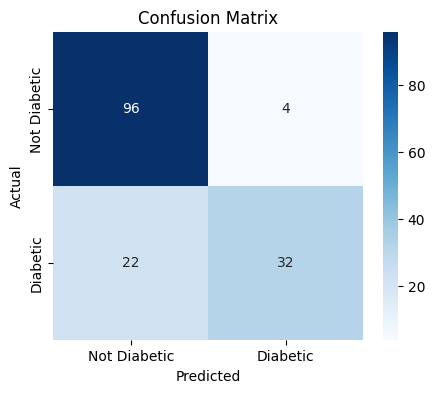

In [24]:
final_coefs = []
final_intercepts = []
global_coef = np.zeros((1, n_features))
global_intercept = np.zeros(1)

for r in range(n_rounds):
    client_weights = []
    for X_c, y_c in client_data:
        coef, intercept = train_local_model(X_c, y_c, global_coef, global_intercept)
        client_weights.append((coef, intercept))
    global_coef, global_intercept = federated_average(client_weights)
    if r >= n_rounds - 5:
        final_coefs.append(global_coef)
        final_intercepts.append(global_intercept)

stable_coef = np.mean(final_coefs, axis=0)
stable_intercept = np.mean(final_intercepts, axis=0)

final_model = LogisticRegression(max_iter=1000)
final_model.coef_ = stable_coef
final_model.intercept_ = stable_intercept
final_model.classes_ = np.array([0, 1])

y_pred = final_model.predict(X_test_scaled)
y_prob = final_model.predict_proba(X_test_scaled)[:, 1]

print("Final Test Accuracy:", accuracy_score(y_test, y_pred))
print("ROC AUC Score:", roc_auc_score(y_test, y_prob))
print(classification_report(y_test, y_pred, target_names=["Not Diabetic", "Diabetic"]))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Not Diabetic", "Diabetic"],
            yticklabels=["Not Diabetic", "Diabetic"])
plt.title("Confusion Matrix")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

In [25]:
import zipfile
import sklearn
import json

with open("global_model.pkl", "wb") as f:
    pickle.dump(final_model, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

np.savez("global_weights.npz", coef=stable_coef, intercept=stable_intercept)

sample_df = X_test.iloc[:10].copy()
sample_df["Outcome"] = y_test.iloc[:10].values
sample_df.to_csv("sample_patients.csv", index=False)

versions = {
    "python": "3.12",
    "scikit-learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__
}
with open("library_versions.json", "w") as f:
    json.dump(versions, f, indent=4)

with zipfile.ZipFile("federated_diabetes_model.zip", "w") as zf:
    zf.write("global_model.pkl")
    zf.write("scaler.pkl")
    zf.write("global_weights.npz")
    zf.write("sample_patients.csv")
    zf.write("library_versions.json")

print("Files packaged into federated_diabetes_model.zip")
print(versions)
sample_df.head()

Files packaged into federated_diabetes_model.zip
{'python': '3.12', 'scikit-learn': '1.6.1', 'pandas': '2.3.3', 'numpy': '2.0.2'}


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
162,0,114,80.0,34,285.0,44.2,0.167,27,0
620,2,112,86.0,42,160.0,38.4,0.246,28,0
233,4,122,68.0,27,102.5,35.0,0.394,29,0
438,1,97,70.0,15,102.5,18.2,0.147,21,0
660,10,162,84.0,27,102.5,27.7,0.182,54,0
